# Homework 2 (part a): Slope limiters for finite volumes in 1D

#### Notebook Submission Deadline: Wednesday 25 November 2026 (by 9pm)

#### Homework Written Defence: Thursday 26 November 2026 (at 1pm)

#### Credits: 25 points

## Name: Silva Alejandro

- When you finish, please submit your notebook via the link provided.

- This homework is individual. Please include your name in the notebook.

- Within a **single python notebook**, solve the following problem:

## Problem 1. Slope limiters for the advection equation

In class we solved the linear advection equation in conservation form,

$$\frac{\partial u}{\partial t} + \frac{\partial F(u)}{\partial x} = 0, \qquad F(u) = c\,u$$

with a finite-volume method: cell averages, ghost cells, a limited slope in each cell, an upwind Riemann solver, and the conservative update:

$$u^{n+1}_i = u^{n}_i + \frac{\Delta t}{\Delta x} \left(F^{n+1/2}_{i-1/2} - F^{n+1/2}_{i+1/2}\right)$$

The interface states are predicted to the half time from the slope in the cell,

$$u^{n+1/2}_{i+1/2,L} = u^{n}_{i} + \frac{\Delta x}{2} \left(1 - c\frac{\Delta t}{\Delta x}\right) \left(\frac{\Delta u}{\Delta x}\right)_{i}, \qquad u^{n+1/2}_{i+1/2,R} = u^{n}_{i+1} - \frac{\Delta x}{2} \left(1 + c\frac{\Delta t}{\Delta x}\right) \left(\frac{\Delta u}{\Delta x}\right)_{i+1}$$

exactly as in **nb14**, where the slope was limited with **minmod** and with **MC**.

In this problem you will add 4 more limiters and evaluate what each one does to the solution.

### Limiters:

Every limiter can be written as a single function $\psi(r)$ of the ratio of successive gradients,

$$r_i = \frac{\Delta u_{L}}{\Delta u_{R}} = \frac{u_i - u_{i-1}}{u_{i+1} - u_i}, \qquad\qquad \left(\frac{\Delta u}{\Delta x}\right)_i = \psi(r_i)\, \frac{u_{i+1} - u_i}{\Delta x}$$

so that one function controls the whole scheme. The two limiters you already know read, in this notation,

$$\psi_{\rm minmod}(r) = \max\left[0,\ \min\left(1,\ r\right)\right], \qquad\qquad \psi_{\rm MC}(r) = \max\left[0,\ \min\left(2r,\ \frac{1 + r}{2},\ 2\right)\right]$$

and the 4 you have to add are:

$$\psi_{\rm vanAlbada}(r) = \begin{cases} \dfrac{r^{2} + r}{r^{2} + 1} & r > 0\\[8pt] 0 & r \leq 0\end{cases} \qquad\qquad \psi_{\rm OSPRE}(r) = \begin{cases} \dfrac{3\left(r^{2} + r\right)}{2\left(r^{2} + r + 1\right)} & r > 0\\[8pt] 0 & r \leq 0\end{cases}$$

$$\psi_{\rm vanLeer}(r) = \frac{r + \left|r\right|}{1 + \left|r\right|}, \qquad\qquad \psi_{\rm UMIST}(r) = \max\left[0,\ \min\left(2r,\ \frac{1 + 3r}{4},\ \frac{3 + r}{4},\ 2\right)\right]$$

These are the 4 limiters commonly offered in hydrodynamic codes.

A limiter is second-order TVD when:

$$\psi(r) = 0 \;\; {\rm for} \;\; r \leq 0, \qquad \psi(1) = 1, \qquad 0 \leq \psi(r) \leq \min\left(2r,\ 2\right)$$

and the region allowed by the last condition is what we call the Sweby diagram.

##### Reference:

- Flux limiters: https://en.wikipedia.org/wiki/Flux_limiter

---
### Coding tasks:

#### Solver and limiters:

#### **(a)** Build the solver with **python functions or python classes** that stores the grid, the ghost cells and the solution, with methods to: set the initial condition, fill periodic boundary conditions, return $\Delta t$ from a CFL number, build the interface states from a limited slope, solve the Riemann problem by upwinding, and do the conservative update. The limiter must be an argument, so that one object runs every case. Use $c = 1$ on $x \in [0, 1]$ with two initial conditions:

$$u_{\rm hat}(x, 0) = \begin{cases} 1 & 1/3 \leq x \leq 2/3\\[3pt] 0 & {\rm otherwise}\end{cases} \qquad\qquad u_{\rm gauss}(x, 0) = e^{-100\left(x - 1/2\right)^{2}}$$

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

# Plot style
import scienceplots
plt.style.use(['science', 'notebook', 'no-latex'])

# Readable fonts and a light grid in every figure
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.4, "grid.linestyle": "--"})

In [ ]:
# Solver class
class LAdvection1D:
    '''
    Finite-volume solver for the linear 1D advection equation on a periodic domain, with a limited slope.
    '''
    # ------------------------------------------------------------------
    # Grid, initial conditions and boundary conditions
    # ------------------------------------------------------------------
    def __init__(self, nx, limiter, c=1.0, xmin=0.0, xmax=1.0, ng=2):
        # Interior cells
        self.nx = nx
        # Ghost cells
        self.ng = ng
        # Advection speed
        self.c = c
        # Left edge of the domain
        self.xmin = xmin
        # Right edge of the domain
        self.xmax = xmax
        # Limiter
        self.limiter = limiter
        # Index of the first interior cell
        self.ilo = ng
        # Index of the last interior cell
        self.ihi = ng + nx - 1
        # Cell width
        self.dx = (xmax - xmin) / nx
        # Cell centres, including the ghost cells
        self.x = xmin + (np.arange(nx + 2*ng) - ng + 0.5) * self.dx
        # Solution vector
        self.u = np.zeros(nx + 2*ng, dtype=np.float64)
        # Current time
        self.t = 0.0
        # Number of steps taken
        self.nsteps = 0

    # ICs
    @staticmethod
    def top_hat(x):
        return np.where(np.logical_and(x >= 1.0/3.0, x <= 2.0/3.0), 1.0, 0.0)

    @staticmethod
    def gaussian(x):
        # Gaussian centred at x = 1/2
        return np.exp(-100.0 * (x - 0.5)**2)

    @classmethod
    def initial_conditions(cls):
        return {"top hat": cls.top_hat, "Gaussian": cls.gaussian}

    def set_initial_condition(self, ic_function):
        '''
        Evaluates the initial condition over the grid.
        '''
        self.ic_function = ic_function
        # Evaluate the profile at every cell centre
        self.u[:] = ic_function(self.x)
        # Keep a copy of the initial data
        self.uinit = self.u.copy()
        # Reset the clock and the step counter
        self.t = 0.0
        self.nsteps = 0

    def fill_bcs(self):
        '''
        Fills the ghost cells with periodic boundary conditions.
        '''
        # Loop over the ghost cells on each side
        for n in range(self.ng):
            # Left ghost cells copy the last interior cells
            self.u[self.ilo - 1 - n] = self.u[self.ihi - n]
            # Right ghost cells copy the first interior cells
            self.u[self.ihi + 1 + n] = self.u[self.ilo + n]

    def interior(self, v=None):
        '''
        Returns the interior cells of an array (no ghost cells)
        '''
        # Interior cells of a vector (of the solution by default)
        if v is None:
            v = self.u
        return v[self.ilo:self.ihi+1]

    # ------------------------------------------------------------------
    # Limiters psi(r)
    # ------------------------------------------------------------------
    @staticmethod
    def gradient_ratio(du_left, du_right, eps=1.0e-14):
        '''
        Computes the ratio of succesive gradients.
        '''
        # Divide by a tiny number to avoid divison by zero
        safe_du_right = np.where(np.abs(du_right) > eps, du_right, eps)
        # r = (u_i - u_{i-1}) / (u_{i+1} - u_i)
        return du_left / safe_du_right

    # Minmod limiter
    @staticmethod
    def psi_minmod(r):
        return np.maximum(0.0, np.minimum(1.0, r))

    # MC limiter
    @staticmethod
    def psi_mc(r):
        # Smallest of 2r, (1 + r)/2 and 2
        smallest = np.minimum(np.minimum(2.0 * r, 0.5 * (1.0 + r)), 2.0)
        # Negative values are cut to zero
        return np.maximum(0.0, smallest)

    # van Albada limiter
    @staticmethod
    def psi_van_albada(r):
        return np.where(r > 0.0, (r**2 + r) / (r**2 + 1.0), 0.0)

    # OSPRE limiter
    @staticmethod
    def psi_ospre(r):
        return np.where(r > 0.0, 1.5 * (r**2 + r) / (r**2 + r + 1.0), 0.0)

    # van Leer limiter
    @staticmethod
    def psi_van_leer(r):
        return (r + np.abs(r)) / (1.0 + np.abs(r))

    # UMIST limiter
    @staticmethod
    def psi_umist(r):
        # First smallest
        smallest = np.minimum(2.0 * r, 0.25 * (1.0 + 3.0 * r))
        # Second smallest
        smallest = np.minimum(smallest, 0.25 * (3.0 + r))
        # Final smallest
        smallest = np.minimum(smallest, 2.0)
        # Negative values are cut to zero
        return np.maximum(0.0, smallest)

    @classmethod
    def limiters(cls):
        '''
        Returns the six limiters in a dictionary.
        Plots, runs and tables loop over this dictionary, so a new limiter only needs to be added here.
        '''
        # The six limiter functions, by name
        return {"minmod": cls.psi_minmod, "MC": cls.psi_mc, "van Albada": cls.psi_van_albada,
                "OSPRE": cls.psi_ospre, "van Leer": cls.psi_van_leer, "UMIST": cls.psi_umist}

    @classmethod
    def schemes(cls):
        '''
        Organizes the eight schemes (Godunov, centred and the six limiters) in a single dictionary that can be accessed easily.
        '''
        all_schemes = {"Godunov": "godunov", "centred": "centred"}
        all_schemes.update(cls.limiters())
        return all_schemes

    # ------------------------------------------------------------------
    # Update step: slope -> interface states -> Riemann -> update
    # ------------------------------------------------------------------
    def timestep(self, cfl):
        # Delta t from the CFL number
        return cfl * self.dx / abs(self.c)

    def slopes(self):
        '''
        Computes the slope in every cell, using the chosen limiter.
        '''
        # Empty vector for the slope (Delta u / Delta x) in each cell
        slope = np.zeros_like(self.u)
        ## Godunov: zero slope
        if isinstance(self.limiter, str) and self.limiter == "godunov":
            return slope

        ## Gradients
        # Left difference for cells 1 ... N-2
        du_left = self.u[1:-1] - self.u[:-2]
        # Right difference for cells 1 ... N-2
        du_right = self.u[2:] - self.u[1:-1]

        ## Unlimited centred difference (u_{i+1} - u_{i-1}) / (2 dx)
        if isinstance(self.limiter, str) and self.limiter == "centred":
            slope[1:-1] = 0.5 * (du_left + du_right) / self.dx
            return slope

        ## Any limiter: slope = psi(r) (u_{i+1} - u_i) / dx
        r = self.gradient_ratio(du_left, du_right)
        slope[1:-1] = self.limiter(r) * du_right / self.dx
        return slope

    def interface_states(self, dt):
        '''
        Computes the left and right states at every interface, predicted to t^{n+1/2} from the slope.
        '''
        # Short names to keep the formulas readable
        ilo, ihi, dx = self.ilo, self.ihi, self.dx
        # Courant number of this step
        C = self.c * dt / dx
        # Limited slope in every cell
        slope = self.slopes()
        # Empty vectors for the left and right states; index i means interface i-1/2
        ul = np.zeros_like(self.u)
        ur = np.zeros_like(self.u)
        # Left state at i-1/2: from cell i-1, moved to its right edge
        ul[ilo:ihi+2] = self.u[ilo-1:ihi+1] + 0.5 * dx * (1.0 - C) * slope[ilo-1:ihi+1]
        # Right state at i-1/2: from cell i, moved to its left edge
        ur[ilo:ihi+2] = self.u[ilo:ihi+2] - 0.5 * dx * (1.0 + C) * slope[ilo:ihi+2]
        return ul, ur

    def riemann(self, ul, ur):
        # Upwinding: for c > 0 the information comes from the left state
        if self.c > 0.0:
            return self.c * ul
        # For c < 0 it comes from the right state
        return self.c * ur

    def conservative_update(self, dt, flux):
        # Short names
        ilo, ihi = self.ilo, self.ihi
        # Conservative update where F_{i-1/2} = flux[i]
        self.u[ilo:ihi+1] = self.u[ilo:ihi+1] + dt / self.dx * (flux[ilo:ihi+1] - flux[ilo+1:ihi+2])

    def advance(self, dt):
        '''
        One finite-volume step.
        '''
        # 1. Periodic boundary conditions
        self.fill_bcs()
        # 2. Interface states from the limited slope
        ul, ur = self.interface_states(dt)
        # 3. Riemann problem (u pwind flux)
        flux = self.riemann(ul, ur)
        # 4. Conservative update
        self.conservative_update(dt, flux)
        # 5. Advance and count the step
        self.t += dt
        self.nsteps += 1

    def evolve(self, tmax, cfl):
        # Loop until the final time
        while self.t < tmax:
            # Time step from the CFL number
            dt = self.timestep(cfl)
            # Shorten the last step so that we land exactly on tmax
            if self.t + dt > tmax:
                dt = tmax - self.t
            # Take the step
            self.advance(dt)

    # ------------------------------------------------------------------
    # Exact solution and errors
    # ------------------------------------------------------------------
    def exact(self):
        '''
        Exact solution at the current time: u(x, t) = u0(x - c t) on the periodic domain.
        '''
        # Domain length
        L = self.xmax - self.xmin
        # Starting position x - c t, wrapped into the domain
        x0 = self.xmin + np.mod(self.x - self.c * self.t - self.xmin, L)
        # Initial profile evaluated at the starting position
        return self.ic_function(x0)

    def errors(self):
        '''
        L1 and L2 errors of the solution against the exact solution, interior cells only.
        '''
        # Difference between the numerical and the exact solution
        diff = self.interior() - self.interior(self.exact())
        # L1 norm: mean absolute error
        E1 = np.mean(np.abs(diff))
        # L2 norm: root-mean-square error
        E2 = np.sqrt(np.mean(diff**2))
        return E1, E2

    # ------------------------------------------------------------------
    # Runner
    # ------------------------------------------------------------------
    @classmethod
    def run(cls, nx, ic_function, limiter, cfl=0.7, num_periods=5):
        '''
        Runs a single simulation with the given parameters.
        '''
        # Build an instance of the class with the chosen scheme
        solver = cls(nx, limiter)
        # Set the initial condition
        solver.set_initial_condition(ic_function)
        # One period is the time to cross the domain once
        period = (solver.xmax - solver.xmin) / abs(solver.c)
        # Evolve for the requested number of periods
        solver.evolve(num_periods * period, cfl)
        return solver

    @classmethod
    def run_all(cls, nx, cfl=0.7, num_periods=5):
        '''
        Runs the eight schemes for both initial conditions.
        Returns a nested dictionary runs[ic_name][scheme_name] of finished solvers.
        ''' 
        # Dictionary to store solutions
        runs = {}
        # Loop over the two initial conditions
        for ic_name, ic in cls.initial_conditions().items():
            # Loop over the eight schemes
            runs[ic_name] = {name: cls.run(nx, ic, lim, cfl, num_periods) for name, lim in cls.schemes().items()}
        return runs

    @classmethod
    def convergence(cls, nx_list, cfl=0.7, num_periods=1):
        '''
        Convergence study: runs the eight schemes for both initial conditions at every nx in nx_list.
        Returns a nested dictionary conv[ic_name][scheme_name] of arrays, one row (E1, E2) per nx.
        '''
        # conv[ic_name][scheme_name] = array (len(nx_list), 2) with E1 and E2
        conv = {}
        # Loop over the two initial conditions
        for ic_name, ic in cls.initial_conditions().items():
            conv[ic_name] = {}
            # Loop over the eight schemes
            for name, lim in cls.schemes().items():
                # Errors at every resolution
                conv[ic_name][name] = np.array([cls.run(nx, ic, lim, cfl, num_periods).errors() for nx in nx_list])
        return conv

    # ------------------------------------------------------------------
    # Checks and tables
    # ------------------------------------------------------------------
    @staticmethod
    def minmod_nb(a, b):
        # minmod function exactly as in nb14
        if abs(a) <= abs(b) and a*b > 0.0:
            return a
        if abs(b) <= abs(a) and a*b > 0.0:
            return b
        else:
            return 0.0

    @classmethod
    def verify_against_nb(cls, npoints=500, seed=2026):
        '''
        Prints the largest difference relative to the mean slope on random data between the psi(r) form\
             and the minmod and MC slopes of nb14.
        '''
        # Random data vector and an arbitrary grid spacing
        data = np.random.default_rng(seed).normal(size=npoints)
        dx = 1.0 / npoints

        ## slopes, cell by cell
        mm_nb = np.zeros(npoints)
        mc_nb = np.zeros(npoints)
        for i in range(1, npoints - 1):
            # nb14 minmod slope
            mm_nb[i] = cls.minmod_nb((data[i] - data[i-1])/dx, (data[i+1] - data[i])/dx)
            # nb14 MC slope
            mc_nb[i] = cls.minmod_nb(cls.minmod_nb(2*(data[i] - data[i-1])/dx, 2*(data[i+1] - data[i])/dx),
                                         0.5*(data[i+1] - data[i-1])/dx)

        ## psi(r) form of the same slopes
        du_left = data[1:-1] - data[:-2]
        du_right = data[2:] - data[1:-1]
        r = cls.gradient_ratio(du_left, du_right)
        mm_psi = np.zeros(npoints)
        mc_psi = np.zeros(npoints)
        mm_psi[1:-1] = cls.psi_minmod(r) * du_right / dx
        mc_psi[1:-1] = cls.psi_mc(r) * du_right / dx
        # Report the largest difference, relative to the typical slope size
        scale = np.abs(mc_nb).mean()
        print("minmod: largest relative difference between nb and psi = %.1e" % (np.abs(mm_nb - mm_psi).max() / scale))
        print("MC    : largest relative difference between nb and psi = %.1e" % (np.abs(mc_nb - mc_psi).max() / scale))

    @classmethod
    def extremes_table(cls, runs, tol=1.0e-12):
        '''
        Table of the min and max of each final solution, and whether it stays
        inside the bounds of the initial data (up to round-off tol).
        '''
        # One row per scheme with the min and max of each profile
        rows = []
        for name in cls.schemes():
            row = {"scheme": name}
            inside = []
            for ic_name, short in [("top hat", "hat"), ("Gaussian", "gauss")]:
                s = runs[ic_name][name]
                # Extremes of the solution
                row[short + " min"] = s.interior().min()
                row[short + " max"] = s.interior().max()
                # Inside the bounds of the initial data?
                ok = (row[short + " min"] >= s.interior(s.uinit).min() - tol) and \
                     (row[short + " max"] <= s.interior(s.uinit).max() + tol)
                inside.append("yes" if ok else "NO")
            # One column "hat / gauss"
            row["bounded (hat / gauss)"] = " / ".join(inside)
            rows.append(row)
        return pd.DataFrame(rows).set_index("scheme").round(5)

    @classmethod
    def error_table(cls, runs):
        '''
        Table of the L1 and L2 errors of each scheme, for both initial conditions.
        '''
        # One row per scheme with E1 and E2 for each profile
        rows = []
        for name in cls.schemes():
            row = {"scheme": name}
            for ic_name, short in [("top hat", "hat"), ("Gaussian", "gauss")]:
                E1, E2 = runs[ic_name][name].errors()
                row[short + " E1"] = E1
                row[short + " E2"] = E2
            rows.append(row)
        return pd.DataFrame(rows).set_index("scheme").style.format("{:.2e}")

    # ------------------------------------------------------------------
    # Figures
    # ------------------------------------------------------------------
    # One colour, line style and line width per scheme, used in every figure
    STYLES = {
        "Godunov":    dict(color="0.45", ls=":", lw=2.6),
        "centred":    dict(color="tab:olive", ls="--", lw=2.4),
        "minmod":     dict(color="tab:red", ls="-", lw=3.0),
        "MC":         dict(color="tab:blue", ls="-", lw=2.6),
        "van Albada": dict(color="tab:green", ls="-.", lw=2.3),
        "OSPRE":      dict(color="tab:purple", ls="--", lw=2.0),
        "van Leer":   dict(color="tab:orange", ls="-.", lw=1.8),
        "UMIST":      dict(color="tab:brown", ls=(0, (5, 1, 1, 1)), lw=1.5),
    }

    @classmethod
    def plot_initial_conditions(cls, nx=256):
        # A grid only to evaluate the profiles
        grid = cls(nx, "godunov")
        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
        for ax, (name, ic) in zip(axes, cls.initial_conditions().items()):
            grid.set_initial_condition(ic)
            ax.plot(grid.interior(grid.x), grid.interior(), "k.-", ms=3)
            ax.set_xlabel(r"$x$")
            ax.set_title("Initial condition: %s ($n_x$ = %d)" % (name, nx))
        axes[0].set_ylabel(r"$u(x, 0)$")
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_sweby(cls):
        '''
        Sweby diagram: the six limiters psi(r) over the TVD and second-order TVD regions.
        '''
        # Values of r and their positive part
        r = np.linspace(-1.0, 4.0, 2001)
        rp = np.maximum(r, 0.0)
        # TVD upper bound min(2r, 2)
        tvd_upper = np.minimum(2.0 * rp, 2.0)
        # Second-order region: between minmod (lower) and superbee (upper)
        second_lower = np.minimum(rp, 1.0)
        second_upper = np.maximum(np.minimum(2.0 * rp, 1.0), np.minimum(rp, 2.0))
        fig, ax = plt.subplots(figsize=(9, 6))
        # Shaded regions
        ax.fill_between(r, 0.0, tvd_upper, color="0.88", label="TVD region")
        ax.fill_between(r, second_lower, second_upper, color="0.70", label="second-order TVD region")
        ax.plot(r, tvd_upper, "k--", lw=0.8, label=r"$\min(2r, 2)$")
        # The six limiters
        for name, psi in cls.limiters().items():
            ax.plot(r, psi(r), label=name, **cls.STYLES[name])
        # The point psi(1) = 1
        ax.plot([1.0], [1.0], "k*", ms=16, zorder=5, label=r"$\psi(1) = 1$")
        ax.set_xlim(-1.0, 4.0)
        ax.set_ylim(-0.1, 2.3)
        ax.set_xlabel(r"$r = (u_i - u_{i-1}) / (u_{i+1} - u_i)$")
        ax.set_ylabel(r"$\psi(r)$")
        ax.set_title("Sweby diagram")
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=10, handlelength=2.0,\
            labelspacing=0.3, borderpad=0.4, frameon=False)
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_final_profiles(cls, runs, ic_name, title=""):
        # 4 rows x 2 columns: two schemes per row
        fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True, sharey=True)
        for ax, name in zip(axes.flat, cls.schemes()):
            s = runs[ic_name][name]
            # Exact solution and numerical solution
            ax.plot(s.interior(s.x), s.interior(s.exact()), "k-", lw=1.0, label="exact")
            ax.plot(s.interior(s.x), s.interior(), label=name, **cls.STYLES[name])
            # Bounds of the initial data
            ax.axhline(s.interior(s.uinit).min(), color="0.6", lw=0.6, ls=":")
            ax.axhline(s.interior(s.uinit).max(), color="0.6", lw=0.6, ls=":")
            ax.legend(loc="upper left", fontsize=10)
        for ax in axes[-1, :]:
            ax.set_xlabel(r"$x$")
        for ax in axes[:, 0]:
            ax.set_ylabel(r"$u$")
        fig.suptitle(ic_name + title, fontsize=14)
        plt.tight_layout()
        plt.show()

    @classmethod
    def plot_convergence(cls, conv, nx_list, nfit=4):
        # Rows: profiles. Columns: E1 and E2
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        nx_list = np.asarray(nx_list)
        for row, ic_name in enumerate(conv):
            for col, norm in enumerate([r"$E_1$", r"$E_2$"]):
                ax = axes[row, col]
                for name in cls.schemes():
                    err = conv[ic_name][name][:, col]
                    # Reference slopes: a straight-line fit on the nfit finest grids
                    p = -np.polyfit(np.log(nx_list[-nfit:]), np.log(err[-nfit:]), 1)[0]
                    ax.loglog(nx_list, err, marker="o", ms=4, label="%s (p = %.2f)" % (name, p), **cls.STYLES[name])
                # Reference lines, anchored at the coarsest grid
                e0 = [conv[ic_name][name][0, col] for name in cls.schemes()]
                ax.loglog(nx_list, 1.5 * max(e0) * (nx_list / nx_list[0])**-1.0, "k--", lw=1.0, label="slope $-1$")
                ax.loglog(nx_list, 0.6 * min(e0) * (nx_list / nx_list[0])**-2.0, "k:", lw=1.4, label="slope $-2$")
                ax.set_xticks(nx_list)
                ax.set_xticklabels([str(n) for n in nx_list])
                ax.set_xlabel(r"$n_x$")
                ax.set_ylabel(norm)
                ax.set_title("%s, %s" % (ic_name, norm))
                ax.legend(fontsize=10, loc="lower left")
        plt.tight_layout()
        plt.show()

    # ------------------------------------------------------------------
    # Animation
    # ------------------------------------------------------------------
    @classmethod
    def animate(cls, limiter_name, nx=512, num_periods=5, cfl=0.7, steps_per_frame=40):
        # Solver with the chosen limiter and the top hat
        s = cls(nx, cls.limiters()[limiter_name])
        s.set_initial_condition(cls.top_hat)
        tmax = num_periods * (s.xmax - s.xmin) / abs(s.c)
        # Frames: time, numerical and exact solution
        frames = [(s.t, s.interior().copy(), s.interior(s.exact()).copy())]
        # Same loop as evolve(), storing a frame every steps_per_frame steps (and the last one)
        while s.t < tmax:
            dt = s.timestep(cfl)
            if s.t + dt > tmax:
                dt = tmax - s.t
            s.advance(dt)
            if s.nsteps % steps_per_frame == 0 or s.t >= tmax:
                frames.append((s.t, s.interior().copy(), s.interior(s.exact()).copy()))
        # Figure with the first frame
        fig, ax = plt.subplots(figsize=(9, 4))
        line_exact, = ax.plot(s.interior(s.x), frames[0][2], "k-", lw=1.0, label="exact")
        line_num, = ax.plot(s.interior(s.x), frames[0][1], label="%s, $n_x$ = %d" % (limiter_name, nx),
                    **cls.STYLES[limiter_name])
        label = ax.text(0.02, 0.92, "", transform=ax.transAxes)
        ax.set_xlim(s.xmin, s.xmax)
        ax.set_ylim(-0.1, 1.15)
        ax.set_xlabel(r"$x$")
        ax.set_ylabel(r"$u$")
        ax.set_title("Top hat, %d periods, CFL = %.1f" % (num_periods, cfl))
        ax.legend(loc="upper right")

        def update(k):
            # Update both curves and the time label of frame k
            t, u, u_exact = frames[k]
            line_exact.set_ydata(u_exact)
            line_num.set_ydata(u)
            label.set_text(r"$t$ = %.2f periods" % t)
            return line_exact, line_num, label

        anim = FuncAnimation(fig, update, frames=len(frames), interval=60, blit=True)
        plt.close(fig)
        return anim

#### **(b)** Write functions for $\psi(r)$ for the 4 new limiters, and also for minmod and MC. Make a high-quality, labeled plot of the six curves for $r \in [-1, 4]$, together with the boundaries of the second-order TVD region (Sweby diagram), and mark the point $\psi(1) = 1$ that every second-order limiter must pass through. Then verify numerically that your $\psi$ form reproduces the minmod and MC slopes of nb14 on a random data vector. (**Hint:** you may need to guard the ratio $r$ where $u_{i+1} - u_i$ vanishes or is very small to avoid divisions by zero.)

```python
@staticmethod
def gradient_ratio(du_left, du_right, eps=1.0e-14):
    '''
    Computes the ratio of succesive gradients.
    '''
    # Divide by a tiny number to avoid divison by zero
    safe_du_right = np.where(np.abs(du_right) > eps, du_right, eps)
    # r = (u_i - u_{i-1}) / (u_{i+1} - u_i)
    return du_left / safe_du_right

# Minmod limiter
@staticmethod
def psi_minmod(r):
    return np.maximum(0.0, np.minimum(1.0, r))

# MC limiter
@staticmethod
def psi_mc(r):
    # Smallest of 2r, (1 + r)/2 and 2
    smallest = np.minimum(np.minimum(2.0 * r, 0.5 * (1.0 + r)), 2.0)
    # Negative values are cut to zero
    return np.maximum(0.0, smallest)

# van Albada limiter
@staticmethod
def psi_van_albada(r):
    return np.where(r > 0.0, (r**2 + r) / (r**2 + 1.0), 0.0)

# OSPRE limiter
@staticmethod
def psi_ospre(r):
    return np.where(r > 0.0, 1.5 * (r**2 + r) / (r**2 + r + 1.0), 0.0)

# van Leer limiter
@staticmethod
def psi_van_leer(r):
    return (r + np.abs(r)) / (1.0 + np.abs(r))

# UMIST limiter
@staticmethod
def psi_umist(r):
    # First smallest
    smallest = np.minimum(2.0 * r, 0.25 * (1.0 + 3.0 * r))
    # Second smallest
    smallest = np.minimum(smallest, 0.25 * (3.0 + r))
    # Final smallest
    smallest = np.minimum(smallest, 2.0)
    # Negative values are cut to zero
    return np.maximum(0.0, smallest)


@classmethod
def plot_sweby(cls):
    '''
    Sweby diagram: the six limiters psi(r) over the TVD and second-order TVD regions.        
    '''
    # Values of r and their positive part
    r = np.linspace(-1.0, 4.0, 2001)
    rp = np.maximum(r, 0.0)
    # TVD upper bound min(2r, 2)
    tvd_upper = np.minimum(2.0 * rp, 2.0)
    # Second-order region: between minmod (lower) and superbee (upper)
    second_lower = np.minimum(rp, 1.0)
    second_upper = np.maximum(np.minimum(2.0 * rp, 1.0), np.minimum(rp, 2.0))
    # Figure
    fig, ax = plt.subplots(figsize=(9, 6))
    # Shaded regions
    ax.fill_between(r, 0.0, tvd_upper, color="0.88", label="TVD region")
    ax.fill_between(r, second_lower, second_upper, color="0.70", label="second-order TVD region")
    ax.plot(r, tvd_upper, "k--", lw=0.8, label=r"$\min(2r, 2)$")
    # The six limiters
    for name, psi in cls.limiters().items():
        ax.plot(r, psi(r), label=name, **cls.STYLES[name])
    # The point psi(1) = 1
    ax.plot([1.0], [1.0], "k*", ms=16, zorder=5, label=r"$\psi(1) = 1$")
    ax.set_xlim(-1.0, 4.0)
    ax.set_ylim(-0.1, 2.3)
    ax.set_xlabel(r"$r = (u_i - u_{i-1}) / (u_{i+1} - u_i)$")
    ax.set_ylabel(r"$\psi(r)$")
    ax.set_title("Sweby diagram")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=10, handlelength=2.0,\
            labelspacing=0.3, borderpad=0.4, frameon=False)
    plt.tight_layout()
    plt.show()
```

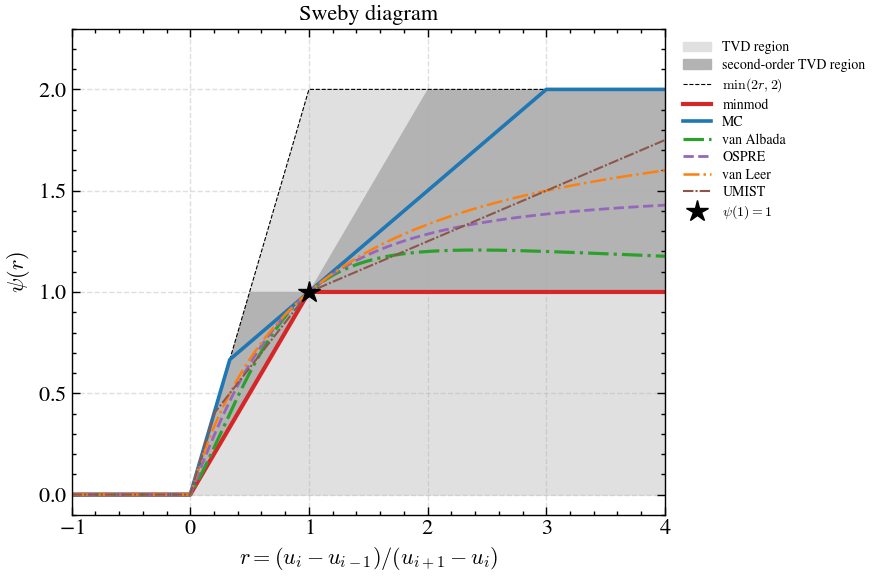

In [3]:
# Sweby diagram with the six limiters
LAdvection1D.plot_sweby()

**Check against nb14.** 

```python
@staticmethod
def minmod_nb(a, b):
    # minmod function exactly as in nb14
    if abs(a) <= abs(b) and a*b > 0.0:
        return a
    if abs(b) <= abs(a) and a*b > 0.0:
        return b
    else:
        return 0.0

@classmethod
def verify_against_nb(cls, npoints=500, seed=2026):
    '''
    Prints the largest difference relative to the mean slope on random data between the psi(r) form and the minmod and MC slopes of nb14.
    '''
    # Random data vector and an arbitrary grid spacing
    data = np.random.default_rng(seed).normal(size=npoints)
    dx = 1.0 / npoints

    ## slopes, cell by cell
    mm_nb = np.zeros(npoints)
    mc_nb = np.zeros(npoints)
    for i in range(1, npoints - 1):
        # nb14 minmod slope
        mm_nb[i] = cls.minmod_nb((data[i] - data[i-1])/dx, (data[i+1] - data[i])/dx)
        # nb14 MC slope
        mc_nb[i] = cls.minmod_nb(cls.minmod_nb(2*(data[i] - data[i-1])/dx, 2*(data[i+1] - data[i])/dx), 0.5*(data[i+1] - data[i-1])/dx)

    ## psi(r) form of the same slopes
    du_left = data[1:-1] - data[:-2]
    du_right = data[2:] - data[1:-1]
    r = cls.gradient_ratio(du_left, du_right)
    mm_psi = np.zeros(npoints)
    mc_psi = np.zeros(npoints)
    mm_psi[1:-1] = cls.psi_minmod(r) * du_right / dx
    mc_psi[1:-1] = cls.psi_mc(r) * du_right / dx
    # Report the largest difference, relative to the typical slope size
    scale = np.abs(mc_nb).mean()
    print("minmod: largest relative difference between nb and psi = %.1e" % (np.abs(mm_nb - mm_psi).max() / scale))
    print("MC    : largest relative difference between nb and psi = %.1e" % (np.abs(mc_nb - mc_psi).max() / scale))
```

In [4]:
# Compare nb14 minmod and MC slopes with the psi(r) form
LAdvection1D.verify_against_nb()

minmod: largest relative difference between nb and psi = 9.7e-16
MC    : largest relative difference between nb and psi = 1.9e-15


#### **(c)** With $n_x = 256$ and ${\rm CFL} = 0.7$, advect both initial conditions for 5 full periods with eight schemes: Godunov (zero slope), the unlimited centred slope, and the six limiters. Make high-quality, labeled figures per each initial condition comparing the final profiles with the exact solution. Report the minimum and the maximum of each solution in a table, and say which schemes stay inside the bounds of the initial data.

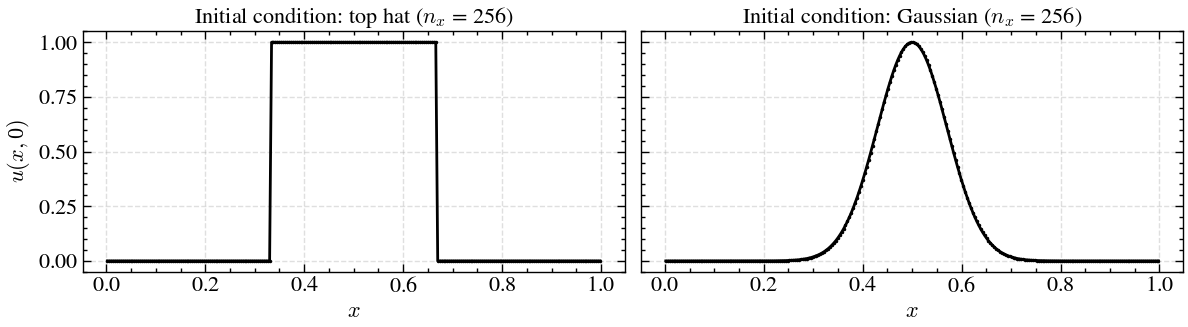

In [5]:
# The two initial conditions on the grid of part (c)
LAdvection1D.plot_initial_conditions(nx=256)

In [6]:
# Run the eight schemes for both profiles
runs_5T = LAdvection1D.run_all(nx=256, cfl=0.7, num_periods=5)

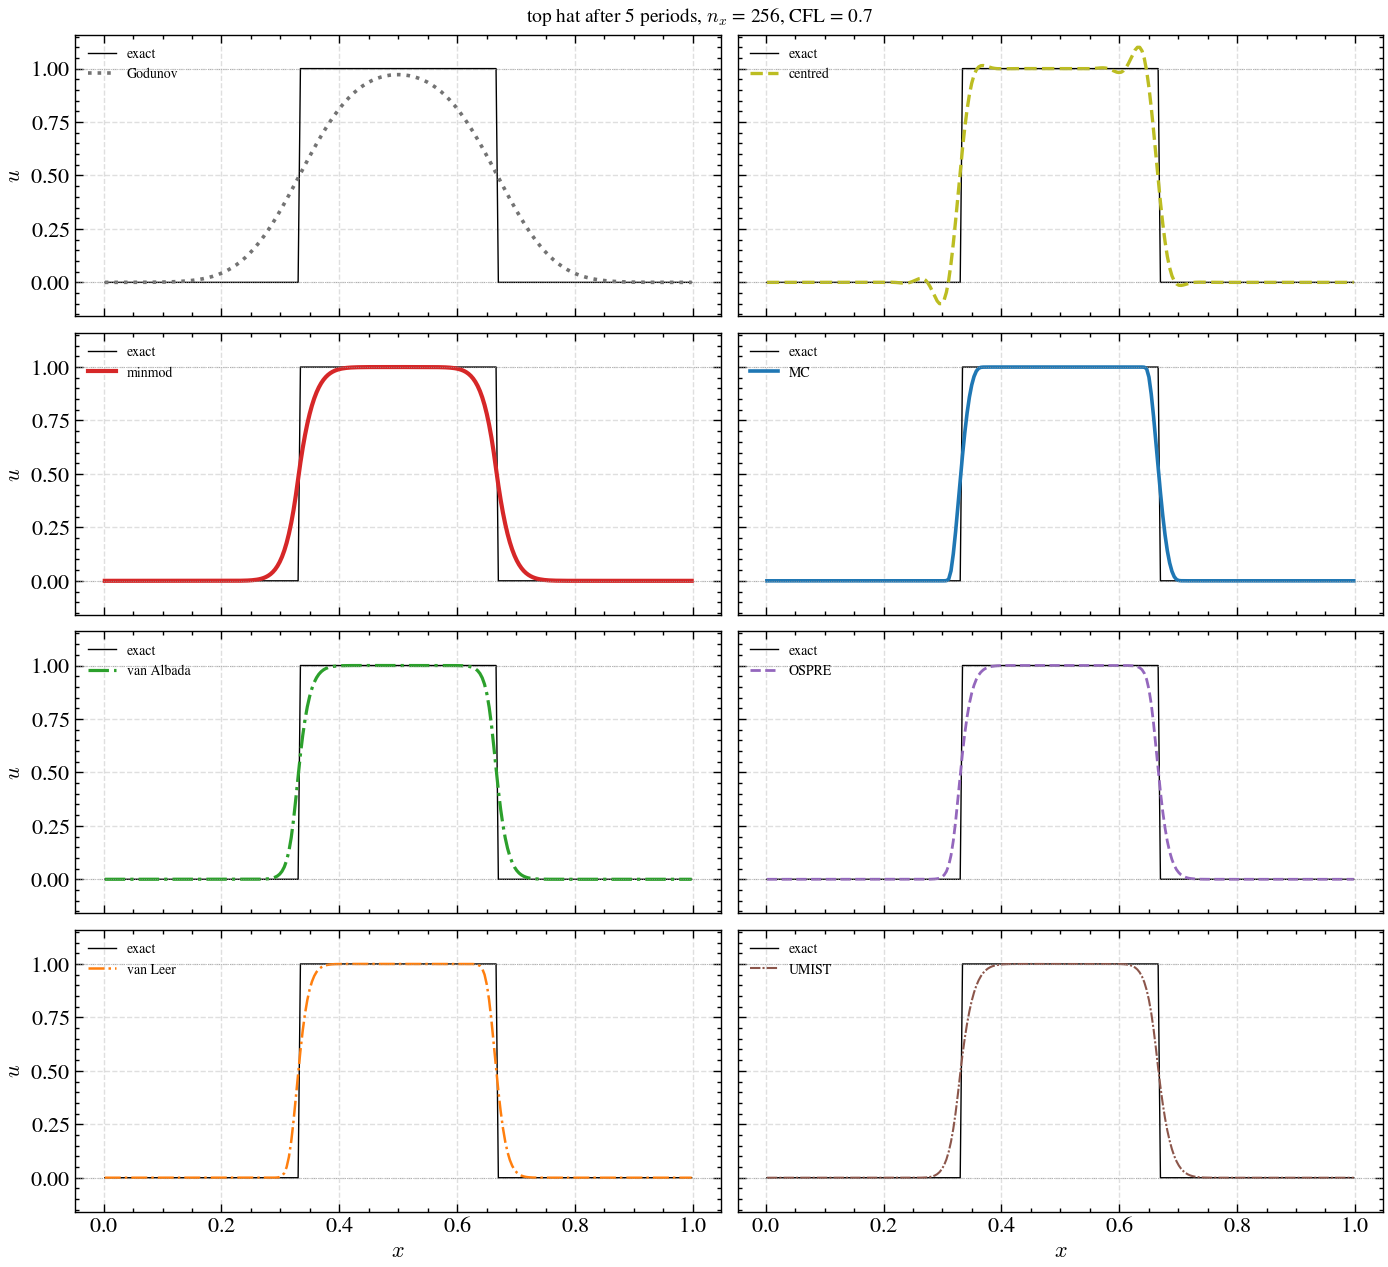

In [7]:
# Final profiles: top hat
LAdvection1D.plot_final_profiles(runs_5T, "top hat", r" after 5 periods, $n_x$ = 256, CFL = 0.7")

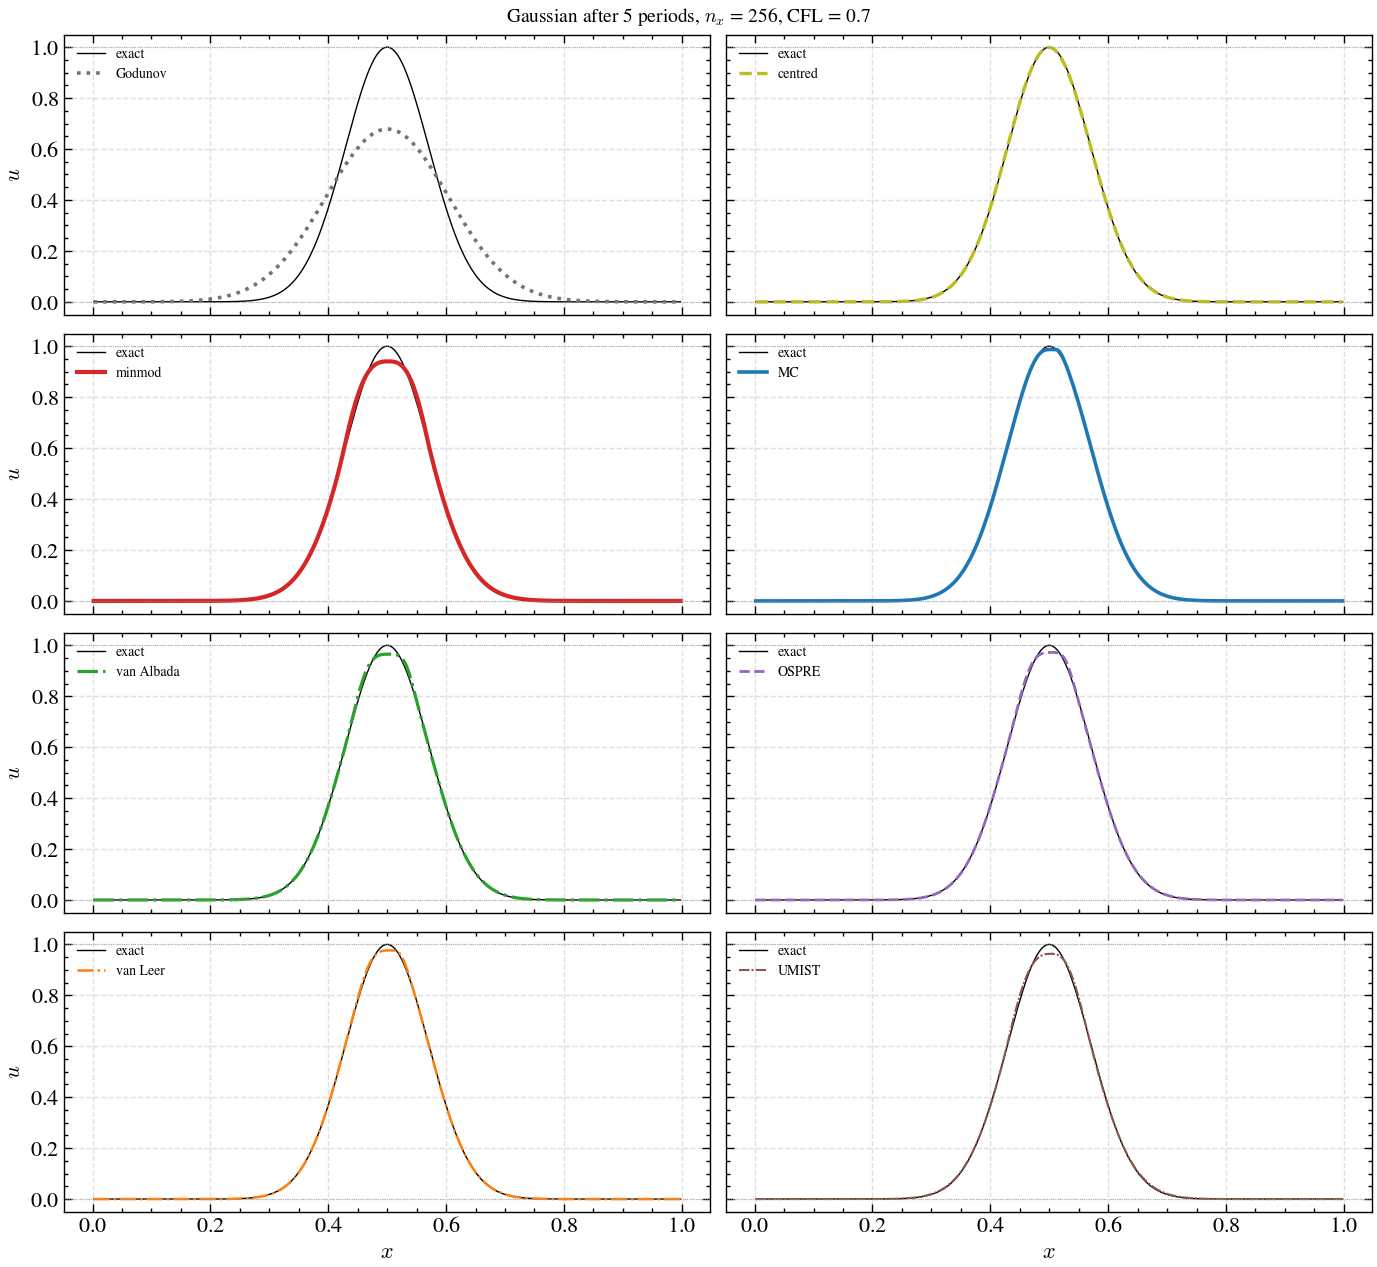

In [8]:
# Final profiles: Gaussian
LAdvection1D.plot_final_profiles(runs_5T, "Gaussian", r" after 5 periods, $n_x$ = 256, CFL = 0.7")

In [9]:
# Minimum and maximum of each solution, and whether it stays inside the initial bounds
display(LAdvection1D.extremes_table(runs_5T))

,hat min,hat max,gauss min,gauss max,bounded (hat / gauss)
scheme,,,,,
Godunov,0.00001,0.97177,0.00001,0.67840,yes / yes
centred,-0.09954,1.09954,0.00000,0.99871,NO / NO
minmod,0.00000,1.00000,0.00000,0.94048,yes / yes
MC,0.00000,1.00000,0.00000,0.98718,yes / yes
van Albada,0.00000,1.00000,0.00000,0.96529,yes / yes
OSPRE,0.00000,1.00000,0.00000,0.97196,yes / yes
van Leer,0.00000,1.00000,0.00000,0.97630,yes / yes
UMIST,0.00000,1.00000,0.00000,0.96300,yes / yes


#### **(d)** Write a function that returns the error of a run against the exact solution in the $L_1$ and $L_2$ norms:

$$E_1 = \frac{1}{N}\sum_{i}\left|u_i - u^{\rm exact}_i\right|, \qquad\qquad E_2 = \left[\frac{1}{N}\sum_{i} \left(u_i - u^{\rm exact}_i\right)^{2}\right]^{1/2}$$

Report $E_1$ and $E_2$ for the eight schemes and the two profiles of point (c). Then repeat the runs for one period at $n_x = 32, 64, 128, 256, 512$ (and also $1024$, if possible), make labeled log-log plots of $E_1$ and $E_2$ against $n_x$ with reference lines of slope $-1$ and $-2$.

```Python
def errors(self):
    '''
    L1 and L2 errors of the solution against the exact solution, interior cells only.
    '''
    # Difference between the numerical and the exact solution
    diff = self.interior() - self.interior(self.exact())
    # L1 norm: mean absolute error
    E1 = np.mean(np.abs(diff))
    # L2 norm: root-mean-square error
    E2 = np.sqrt(np.mean(diff**2))
    return E1, E2

@classmethod
def error_table(cls, runs):
    '''
    Table of the L1 and L2 errors of each scheme, for both initial conditions.
    '''
    # One row per scheme with E1 and E2 for each profile
    rows = []
    for name in cls.schemes():
        row = {"scheme": name}
        for ic_name, short in [("top hat", "hat"), ("Gaussian", "gauss")]:
            E1, E2 = runs[ic_name][name].errors()
            row[short + " E1"] = E1
            row[short + " E2"] = E2
        rows.append(row)
    return pd.DataFrame(rows).set_index("scheme").style.format("{:.2e}")

@classmethod
def convergence(cls, nx_list, cfl=0.7, num_periods=1):
    '''
    Convergence study: runs the eight schemes for both initial conditions at every nx in nx_list.
    Returns a nested dictionary conv[ic_name][scheme_name] of arrays, one row (E1, E2) per nx.
    '''
    # conv[ic_name][scheme_name] = array (len(nx_list), 2) with E1 and E2
    conv = {}
    # Loop over the two initial conditions
    for ic_name, ic in cls.initial_conditions().items():
        conv[ic_name] = {}
        # Loop over the eight schemes
        for name, lim in cls.schemes().items():
            # Errors at every resolution
            conv[ic_name][name] = np.array([cls.run(nx, ic, lim, cfl, num_periods).errors() for nx in nx_list])
    return conv

@classmethod
def plot_convergence(cls, conv, nx_list, nfit=4):
    # Rows: profiles. Columns: E1 and E2
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    nx_list = np.asarray(nx_list)
    for row, ic_name in enumerate(conv):
        for col, norm in enumerate([r"$E_1$", r"$E_2$"]):
            ax = axes[row, col]
            for name in cls.schemes():
                err = conv[ic_name][name][:, col]
                # Reference slopes: a straight-line fit on the nfit finest grids
                p = -np.polyfit(np.log(nx_list[-nfit:]), np.log(err[-nfit:]), 1)[0]
                ax.loglog(nx_list, err, marker="o", ms=4, label="%s (p = %.2f)" % (name, p), **cls.STYLES[name])
            # Reference lines, anchored at the coarsest grid
            e0 = [conv[ic_name][name][0, col] for name in cls.schemes()]
            ax.loglog(nx_list, 1.5 * max(e0) * (nx_list / nx_list[0])**-1.0, "k--", lw=1.0, label="slope $-1$")
            ax.loglog(nx_list, 0.6 * min(e0) * (nx_list / nx_list[0])**-2.0, "k:", lw=1.4, label="slope $-2$")
            ax.set_xticks(nx_list)
            ax.set_xticklabels([str(n) for n in nx_list])
            ax.set_xlabel(r"$n_x$")
            ax.set_ylabel(norm)
            ax.set_title("%s, %s" % (ic_name, norm))
            ax.legend(fontsize=10, loc="lower left")
    plt.tight_layout()
    plt.show()
```

In [10]:
# E1 and E2 of the 5-period runs of part (c)
display(LAdvection1D.error_table(runs_5T))

,hat E1,hat E2,gauss E1,gauss E2
scheme,,,,
Godunov,1.22e-01,1.89e-01,6.57e-02,1.06e-01
centred,2.56e-02,8.25e-02,5.96e-04,1.08e-03
minmod,3.91e-02,1.03e-01,5.19e-03,1.22e-02
MC,1.92e-02,7.67e-02,9.09e-04,2.12e-03
van Albada,2.68e-02,8.61e-02,2.24e-03,6.52e-03
OSPRE,2.45e-02,8.34e-02,1.74e-03,4.97e-03
van Leer,2.31e-02,8.19e-02,1.46e-03,4.05e-03
UMIST,3.05e-02,9.22e-02,2.94e-03,7.10e-03


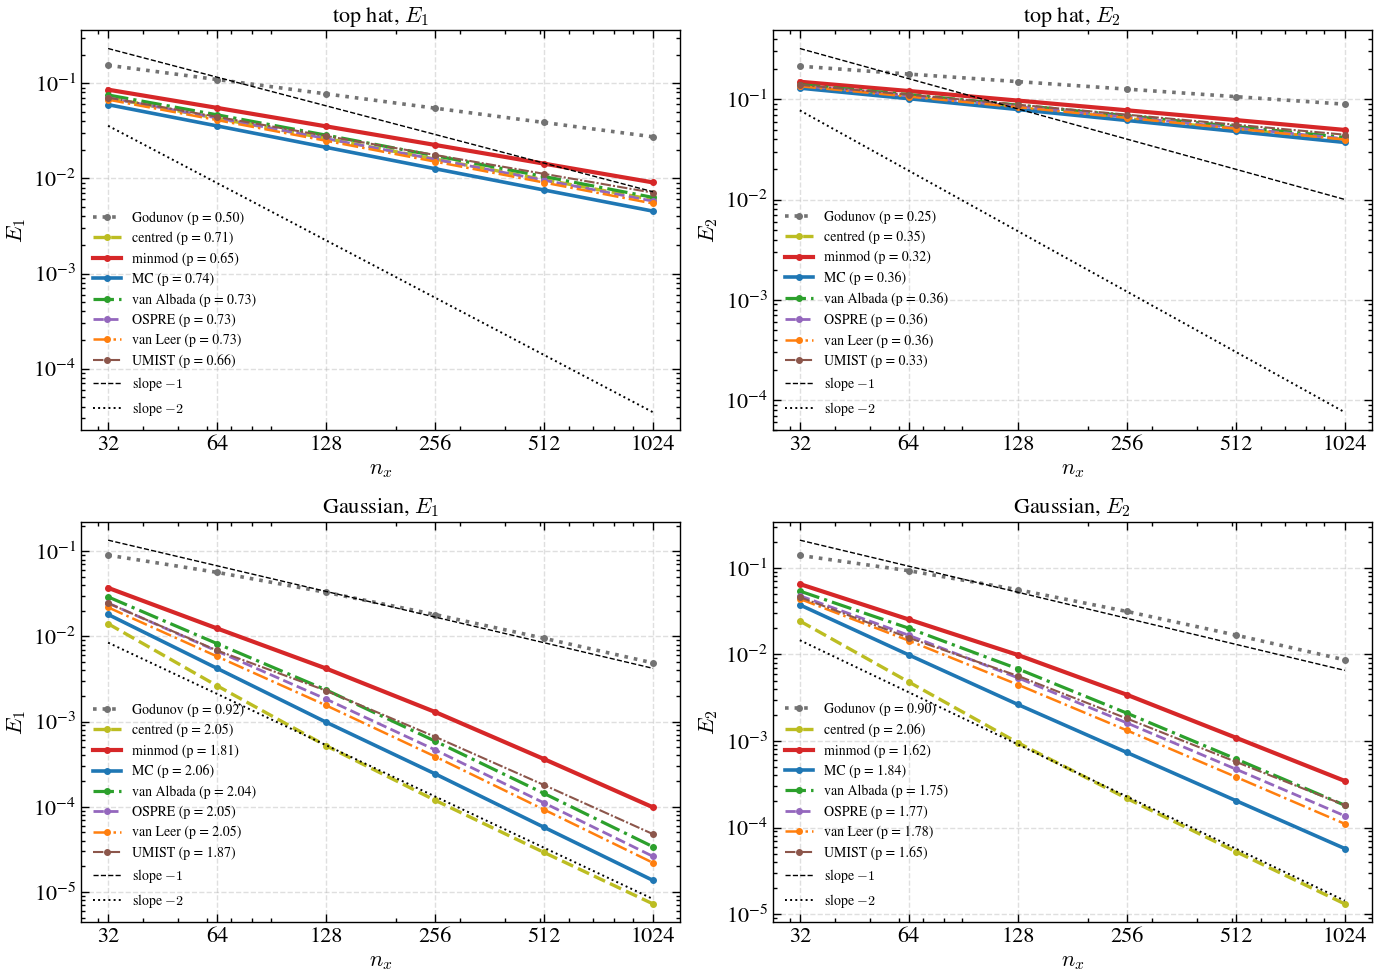

In [11]:
# Convergence study: one period at nx = 32 ... 1024
nx_list = [32, 64, 128, 256, 512, 1024]
conv = LAdvection1D.convergence(nx_list, cfl=0.7, num_periods=1)
LAdvection1D.plot_convergence(conv, nx_list)

### Analysis questions:

#### **(e)** Answer in your own words the following questions, using your figures and results:

### Which limiter is the most accurate for the Gaussian, and which one for the top hat? Are they the same? Why?

For the Gaussian profile the most accurate scheme was the MC limiter with a second order accuracy, according to the plots presented. In the case of the top hat the best limiter was the MC too because is the most compressive, so it keeps the jumps sharpest. 

### What does the unlimited centred slope do to the top hat, and what does Godunov's theorem indicate about it? How does the same scheme behave for the Gaussian? Why?

On the top hat, the centred slope overshoots to $1.0995$ and undershoots to $-0.0995$. Godunov's theorem states that a linear scheme (one that applies the same formula everywhere) cannot be both monotone and more than first order. The centred scheme is linear and second order, so it must oscillate at the jumps. On the smooth Gaussian it is the most accurate scheme ($E_1 = 5.96\times10^{-4}$, order $2.05$), because no limiter cuts its slope at the peak.

### How does your measured order of accuracy for the top hat compare to order $2$ for different limiters?

For the top hat no limiter reaches order 2. The measured order is $p(E_1) \approx 0.65$–$0.74$ and $p(E_2) \approx 0.32$–$0.36$ (MC the highest, minmod the lowest). The jumps on the profile limit the accuracy so at a discontinuity every limiter falls back close to first order.

### Order and list the 6 limiters from the most diffusive to the most compressive, using your own numbers, and relate that order to where each curve sits inside the Sweby diagram of point (b).

The $E_1$ errors of the top hat in the error table of part (d) (5 periods, $n_x = 256$) give the following order, from the most diffusive to the most compressive:

1. minmod ($3.91\times10^{-2}$)
2. UMIST ($3.05\times10^{-2}$)
3. van Albada ($2.68\times10^{-2}$)
4. OSPRE ($2.45\times10^{-2}$)
5. van Leer ($2.31\times10^{-2}$)
6. MC ($1.92\times10^{-2}$)

The Gaussian gives the same order. The order follows the Sweby diagram of part b), the higher a curve sits, the steeper the slopes it allows and the less it smears. minmod lies on the lower edge of the second-order region, van Albada, OSPRE and van Leer follow their curves for $r > 1$, and MC lies highest.

### The van Albada and OSPRE limiters are smooth functions of $r$, while minmod, MC and UMIST are built from $\min$ and $\max$. What practical advantage does a smooth limiter have in a code that also computes derivatives of the solution?

The Sweby diagram of point (b) shows that the minmod, MC and UMIST curves have corners, while van Albada and OSPRE bend smoothly. Limiters built from $\min$ and $\max$ have corners where their derivative jumps, so any derivative of the solution with respect to the data jumps too when a cell switches branch, which can slow down convergence. Smooth limiters like van Albada and OSPRE are differentiable for $r > 0$, so those derivatives are well defined and the solvers converge more reliably.

#### **(f)** Create and display a GIF animation. Take the limiter that came out best for the top hat, advect it again for the 5 periods at $n_x = 512$, and save one frame every few steps as a GIF. Keep the exact profile in the frame as a reference, display the GIF in the notebook, and write one or two lines on what it shows. (**Note:** if the GIF makes your notebook too heavy to submit, comment out the line that saves it and leave the rest of the cell in place.)

Best limiter for the top hat: MC


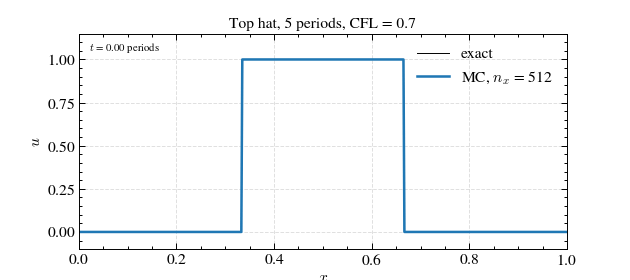

In [12]:
# Best limiter for the top hat: smallest E1 after 5 periods among the six limiters
best = min(LAdvection1D.limiters(), key=lambda name: runs_5T["top hat"][name].errors()[0])
print("Best limiter for the top hat:", best)

# Advect the top hat for 5 periods at nx = 512, one frame every 20 steps
anim = LAdvection1D.animate(best, nx=512, num_periods=5, cfl=0.7, steps_per_frame=20)

# Save the GIF (comment out this line if the notebook becomes too heavy)
anim.save("tophat_best_limiter.gif", writer=PillowWriter(fps=15), dpi=70)

# Show the GIF if it was saved
if os.path.exists("tophat_best_limiter.gif"):
    display(Image(filename="tophat_best_limiter.gif"))

MC keeps the edges sharp, with no oscillations and the solution within $[0, 1]$. Only the corners are still slightly rounded, where the limiter cuts the slope to zero and the scheme is locally first order.